# Import dữ liệu


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

In [3]:
df = pd.read_csv('./data/salary.csv')
df

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,salary
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,<=50K
32557,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,>50K
32558,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K
32559,22,Private,201490,HS-grad,9,Never-married,Adm-clerical,Own-child,White,Male,0,0,20,United-States,<=50K


# Hiển thị thông tin dữ liệu

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       32561 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education-num   32561 non-null  int64 
 5   marital-status  32561 non-null  object
 6   occupation      32561 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital-gain    32561 non-null  int64 
 11  capital-loss    32561 non-null  int64 
 12  hours-per-week  32561 non-null  int64 
 13  native-country  32561 non-null  object
 14  salary          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


In [5]:
df.describe()

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
count,32561.000000,3.256100e+04,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,1.897784e+05,10.080679,1077.648844,87.303830,40.437456
std,13.640433,1.055500e+05,2.572720,7385.292085,402.960219,12.347429
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.370510e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000


# Tiền xử lý dữ liệu

In [6]:
df[10:30]

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,salary
10,37,Private,280464,Some-college,10,Married-civ-spouse,Exec-managerial,Husband,Black,Male,0,0,80,United-States,>50K
11,30,State-gov,141297,Bachelors,13,Married-civ-spouse,Prof-specialty,Husband,Asian-Pac-Islander,Male,0,0,40,India,>50K
12,23,Private,122272,Bachelors,13,Never-married,Adm-clerical,Own-child,White,Female,0,0,30,United-States,<=50K
13,32,Private,205019,Assoc-acdm,12,Never-married,Sales,Not-in-family,Black,Male,0,0,50,United-States,<=50K
14,40,Private,121772,Assoc-voc,11,Married-civ-spouse,Craft-repair,Husband,Asian-Pac-Islander,Male,0,0,40,?,>50K
15,34,Private,245487,7th-8th,4,Married-civ-spouse,Transport-moving,Husband,Amer-Indian-Eskimo,Male,0,0,45,Mexico,<=50K
16,25,Self-emp-not-inc,176756,HS-grad,9,Never-married,Farming-fishing,Own-child,White,Male,0,0,35,United-States,<=50K
17,32,Private,186824,HS-grad,9,Never-married,Machine-op-inspct,Unmarried,White,Male,0,0,40,United-States,<=50K
18,38,Private,28887,11th,7,Married-civ-spouse,Sales,Husband,White,Male,0,0,50,United-States,<=50K
19,43,Self-emp-not-inc,292175,Masters,14,Divorced,Exec-managerial,Unmarried,White,Female,0,0,45,United-States,>50K


In [7]:
# Loại bỏ các dấu "?" có trong data
for index, row in df.iterrows():
    if (row["native-country"] == " ?"):
        df.drop(index, inplace = True)
for index, row in df.iterrows():
    if (row["salary"] == " ?"):
        df.drop(index, inplace = True)
for index, row in df.iterrows():
    if (row["age"] == " ?"):
        df.drop(index, inplace = True)
for index, row in df.iterrows():
    if (row["workclass"] == " ?"):
        df.drop(index, inplace = True)
for index, row in df.iterrows():
    if (row["fnlwgt"] == " ?"):
        df.drop(index, inplace = True)
for index, row in df.iterrows():
    if (row["education"] == " ?"):
        df.drop(index, inplace = True)
for index, row in df.iterrows():
    if (row["education-num"] == " ?"):
        df.drop(index, inplace = True)
for index, row in df.iterrows():
    if (row["marital-status"] == " ?"):
        df.drop(index, inplace = True)
for index, row in df.iterrows():
    if (row["occupation"] == " ?"):
        df.drop(index, inplace = True)
for index, row in df.iterrows():
    if (row["relationship"] == " ?"):
        df.drop(index, inplace = True)
for index, row in df.iterrows():
    if (row["race"] == " ?"):
        df.drop(index, inplace = True)
for index, row in df.iterrows():
    if (row["sex"] == " ?"):
        df.drop(index, inplace = True)
for index, row in df.iterrows():
    if (row["capital-gain"] == " ?"):
        df.drop(index, inplace = True)
for index, row in df.iterrows():
    if (row["capital-loss"] == " ?"):
        df.drop(index, inplace = True)
for index, row in df.iterrows():
    if (row["hours-per-week"] == " ?"):
        df.drop(index, inplace = True)
for index, row in df.iterrows():
    if (row["salary"] == " ?"):
        df.drop(index, inplace = True)

In [8]:
df[10:30]

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,salary
10,37,Private,280464,Some-college,10,Married-civ-spouse,Exec-managerial,Husband,Black,Male,0,0,80,United-States,>50K
11,30,State-gov,141297,Bachelors,13,Married-civ-spouse,Prof-specialty,Husband,Asian-Pac-Islander,Male,0,0,40,India,>50K
12,23,Private,122272,Bachelors,13,Never-married,Adm-clerical,Own-child,White,Female,0,0,30,United-States,<=50K
13,32,Private,205019,Assoc-acdm,12,Never-married,Sales,Not-in-family,Black,Male,0,0,50,United-States,<=50K
15,34,Private,245487,7th-8th,4,Married-civ-spouse,Transport-moving,Husband,Amer-Indian-Eskimo,Male,0,0,45,Mexico,<=50K
16,25,Self-emp-not-inc,176756,HS-grad,9,Never-married,Farming-fishing,Own-child,White,Male,0,0,35,United-States,<=50K
17,32,Private,186824,HS-grad,9,Never-married,Machine-op-inspct,Unmarried,White,Male,0,0,40,United-States,<=50K
18,38,Private,28887,11th,7,Married-civ-spouse,Sales,Husband,White,Male,0,0,50,United-States,<=50K
19,43,Self-emp-not-inc,292175,Masters,14,Divorced,Exec-managerial,Unmarried,White,Female,0,0,45,United-States,>50K
20,40,Private,193524,Doctorate,16,Married-civ-spouse,Prof-specialty,Husband,White,Male,0,0,60,United-States,>50K


In [9]:
df

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,salary
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,<=50K
32557,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,>50K
32558,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K
32559,22,Private,201490,HS-grad,9,Never-married,Adm-clerical,Own-child,White,Male,0,0,20,United-States,<=50K


In [10]:
# xóa 2 cột "capital-gain", "capital-loss"
df_after_drop = df.drop(["capital-gain","capital-loss"], axis=1)

In [11]:
df_after_drop

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,hours-per-week,native-country,salary
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,40,Cuba,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,38,United-States,<=50K
32557,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,40,United-States,>50K
32558,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,40,United-States,<=50K
32559,22,Private,201490,HS-grad,9,Never-married,Adm-clerical,Own-child,White,Male,20,United-States,<=50K


In [12]:
# xóa các bản ghi trùng lặp
df_after_drop.drop_duplicates(inplace=True)

In [13]:
df_after_drop

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,hours-per-week,native-country,salary
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,40,Cuba,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,38,United-States,<=50K
32557,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,40,United-States,>50K
32558,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,40,United-States,<=50K
32559,22,Private,201490,HS-grad,9,Never-married,Adm-clerical,Own-child,White,Male,20,United-States,<=50K


In [14]:
# reset lại index cho các bản ghi
df_after_drop.reset_index(inplace=True, drop=True)

In [15]:
df_after_drop

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,hours-per-week,native-country,salary
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,40,Cuba,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...
30132,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,38,United-States,<=50K
30133,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,40,United-States,>50K
30134,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,40,United-States,<=50K
30135,22,Private,201490,HS-grad,9,Never-married,Adm-clerical,Own-child,White,Male,20,United-States,<=50K


In [2]:
# xuất thành file csv mới
df_after_drop.to_csv('./data/cleaned_salary.csv', index=False)

NameError: name 'df_after_drop' is not defined

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

In [3]:
df_new = pd.read_csv('./data/cleaned_salary.csv')

<Axes: xlabel='salary'>

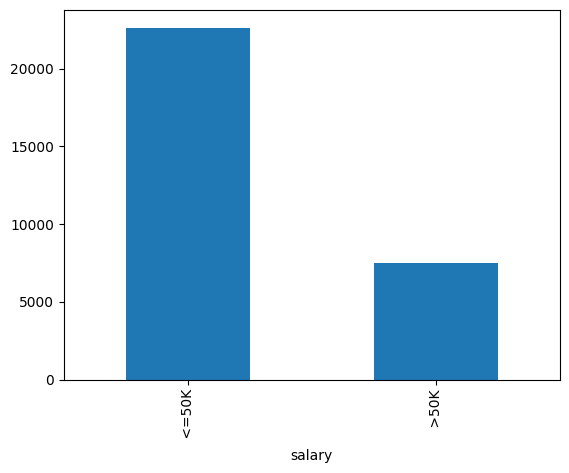

In [ ]:
df_new['salary'].value_counts().plot(kind="bar")
	# age	workclass	fnlwgt	education	education-num	marital-status	occupation	relationship	race	sex	hours-per-week	native-country	salary

<Axes: xlabel='native-country'>

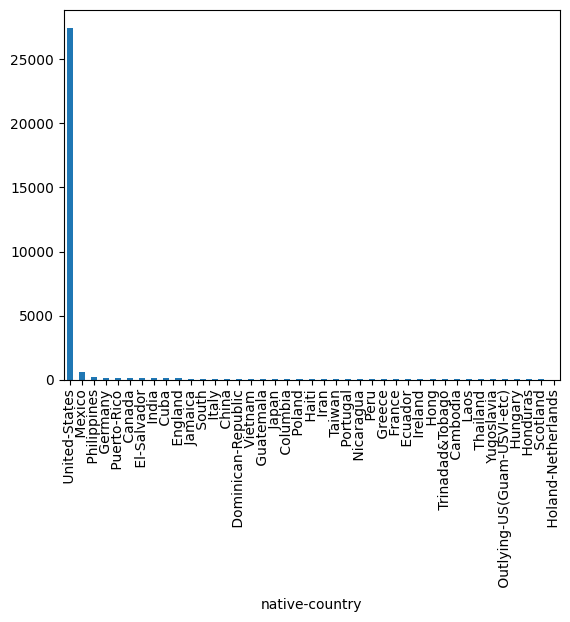

In [19]:
df_new['native-country'].value_counts().plot(kind="bar")

<Axes: xlabel='education'>

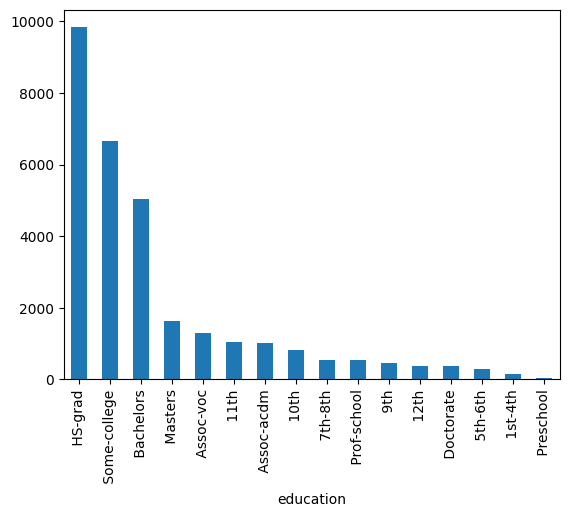

In [20]:
df_new['education'].value_counts().plot(kind="bar")

<Axes: xlabel='education-num'>

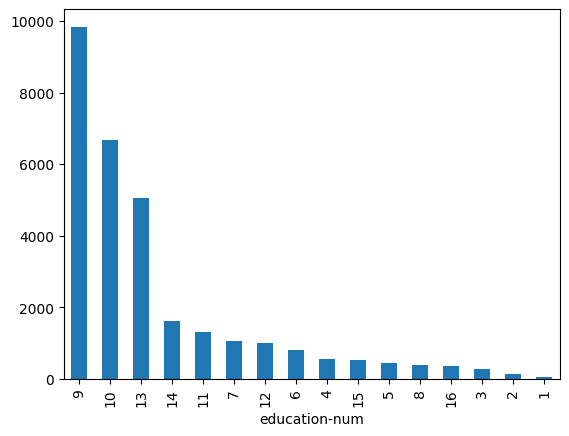

In [21]:
df_new['education-num'].value_counts().plot(kind="bar")

<Axes: xlabel='occupation'>

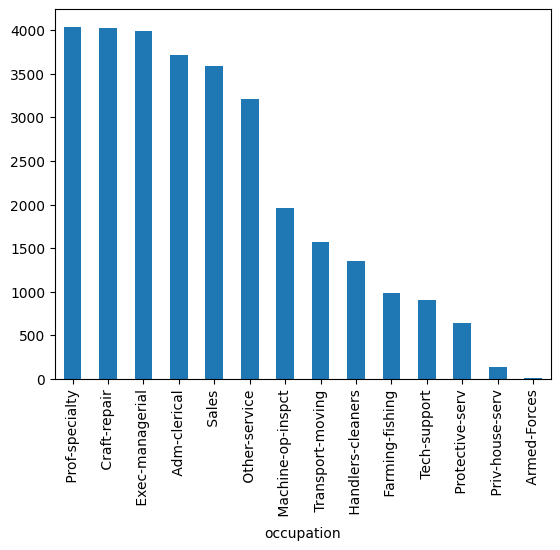

In [22]:
df_new['occupation'].value_counts().plot(kind="bar")

<Axes: xlabel='sex'>

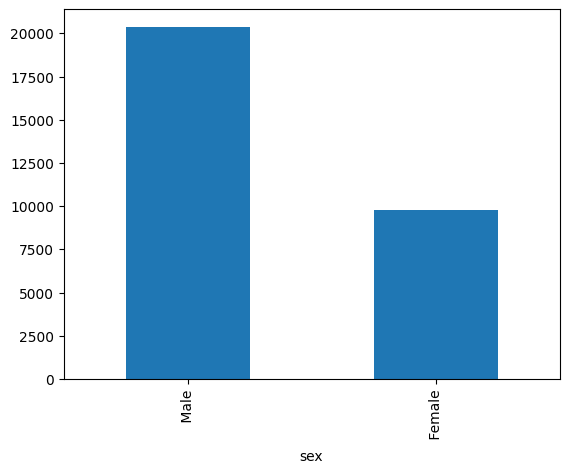

In [23]:
df_new['sex'].value_counts().plot(kind="bar")

<Axes: xlabel='marital-status'>

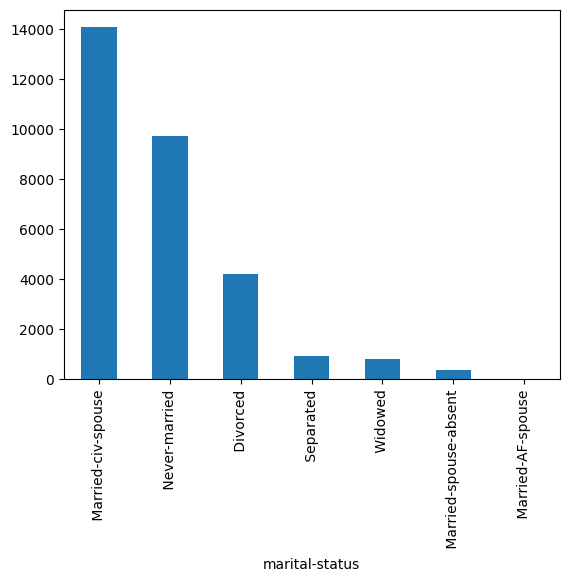

In [24]:
# age	workclass	fnlwgt	education	education-num	marital-status	occupation	relationship	race	sex	hours-per-week	native-country	salary
df_new['marital-status'].value_counts().plot(kind="bar")

<Axes: xlabel='relationship'>

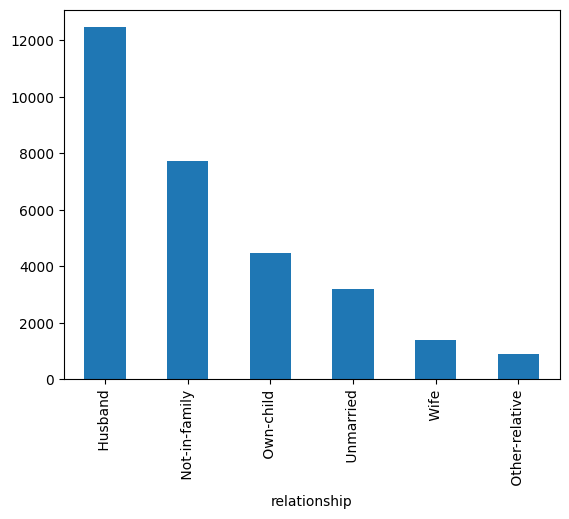

In [25]:
# age	workclass	fnlwgt	education	education-num	marital-status	occupation	relationship	race	sex	hours-per-week	native-country	salary
df_new['relationship'].value_counts().plot(kind="bar")

<Axes: xlabel='race'>

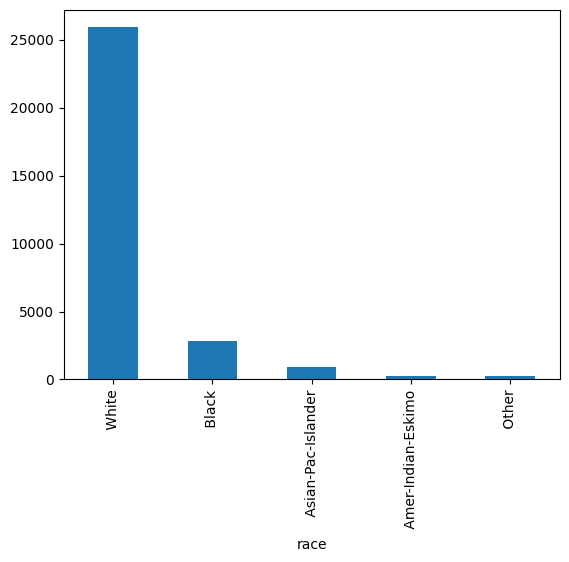

In [26]:
# age	workclass	fnlwgt	education	education-num	marital-status	occupation	relationship	race	sex	hours-per-week	native-country	salary
df_new['race'].value_counts().plot(kind="bar")

<Axes: xlabel='workclass'>

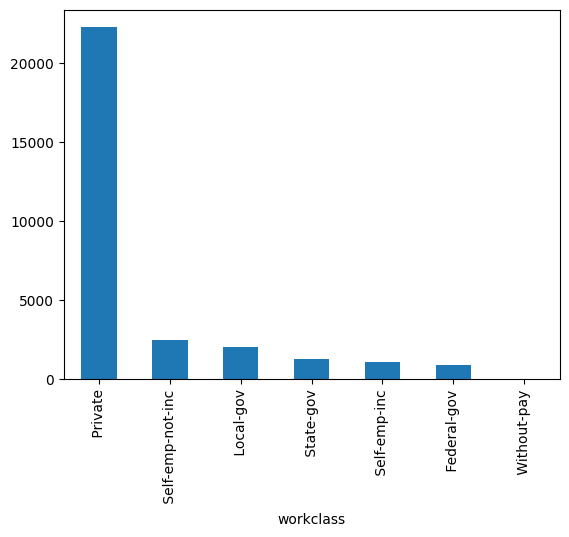

In [27]:
# age	workclass	fnlwgt	education	education-num	marital-status	occupation	relationship	race	sex	hours-per-week	native-country	salary
df_new['workclass'].value_counts().plot(kind="bar")

# Đánh nhãn cho dữ liệu

In [4]:
# đánh nhãn cho y
df_new["salary"] = (df_new["salary"] == " >50K").astype(int)

In [5]:
df_new["salary"]

0        0
1        0
2        0
3        0
4        0
        ..
30132    0
30133    1
30134    0
30135    0
30136    1
Name: salary, Length: 30137, dtype: int64

In [6]:
# đánh nhãn cho X
dataset_dummy = pd.get_dummies(df_new,drop_first=True).astype(int)
dataset_dummy

,age,fnlwgt,education-num,hours-per-week,salary,workclass_ Local-gov,workclass_ Private,workclass_ Self-emp-inc,workclass_ Self-emp-not-inc,workclass_ State-gov,...,native-country_ Portugal,native-country_ Puerto-Rico,native-country_ Scotland,native-country_ South,native-country_ Taiwan,native-country_ Thailand,native-country_ Trinadad&Tobago,native-country_ United-States,native-country_ Vietnam,native-country_ Yugoslavia
0,39,77516,13,40,0,0,0,0,0,1,...,0,0,0,0,0,0,0,1,0,0
1,50,83311,13,13,0,0,0,0,1,0,...,0,0,0,0,0,0,0,1,0,0
2,38,215646,9,40,0,0,1,0,0,0,...,0,0,0,0,0,0,0,1,0,0
3,53,234721,7,40,0,0,1,0,0,0,...,0,0,0,0,0,0,0,1,0,0
4,28,338409,13,40,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
30132,27,257302,12,38,0,0,1,0,0,0,...,0,0,0,0,0,0,0,1,0,0
30133,40,154374,9,40,1,0,1,0,0,0,...,0,0,0,0,0,0,0,1,0,0
30134,58,151910,9,40,0,0,1,0,0,0,...,0,0,0,0,0,0,0,1,0,0
30135,22,201490,9,20,0,0,1,0,0,0,...,0,0,0,0,0,0,0,1,0,0


# Chia dữ liệu để huấn luyện

In [7]:
# 80% train, 20% test
X = dataset_dummy.drop(["salary"],axis=1)
y = dataset_dummy['salary']

X_train, X_test, y_train, y_test = train_test_split(X, y , test_size = 0.2, random_state=42)

# Đưa dữ liệu dạng số có sự chênh lệch lớn về [0, 1]

In [8]:
X_train

,age,fnlwgt,education-num,hours-per-week,workclass_ Local-gov,workclass_ Private,workclass_ Self-emp-inc,workclass_ Self-emp-not-inc,workclass_ State-gov,workclass_ Without-pay,...,native-country_ Portugal,native-country_ Puerto-Rico,native-country_ Scotland,native-country_ South,native-country_ Taiwan,native-country_ Thailand,native-country_ Trinadad&Tobago,native-country_ United-States,native-country_ Vietnam,native-country_ Yugoslavia
2290,54,240542,10,48,0,1,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
4472,33,159548,12,40,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
5478,32,162604,9,40,0,1,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
27308,39,142897,11,50,0,0,0,0,1,0,...,0,0,0,0,0,0,0,1,0,0
28146,19,261422,10,40,0,0,0,0,1,0,...,0,0,0,0,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29802,41,64506,9,50,0,0,1,0,0,0,...,0,0,0,0,0,0,0,1,0,0
5390,37,323155,2,85,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
860,37,176900,9,99,0,1,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
15795,49,124672,9,40,0,1,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0


In [9]:
scaler = MinMaxScaler()
scaler.fit(X_train[['age', 'fnlwgt', 'education-num', 'hours-per-week']])
X_train[['age', 'fnlwgt', 'education-num', 'hours-per-week']]= scaler.transform(X_train[['age', 'fnlwgt', 'education-num', 'hours-per-week']])
X_test[['age', 'fnlwgt', 'education-num', 'hours-per-week']] = scaler.transform(X_test[['age', 'fnlwgt', 'education-num', 'hours-per-week']])

In [10]:
X_train

,age,fnlwgt,education-num,hours-per-week,workclass_ Local-gov,workclass_ Private,workclass_ Self-emp-inc,workclass_ Self-emp-not-inc,workclass_ State-gov,workclass_ Without-pay,...,native-country_ Portugal,native-country_ Puerto-Rico,native-country_ Scotland,native-country_ South,native-country_ Taiwan,native-country_ Thailand,native-country_ Trinadad&Tobago,native-country_ United-States,native-country_ Vietnam,native-country_ Yugoslavia
2290,0.506849,0.154169,0.600000,0.479592,0,1,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
4472,0.219178,0.099106,0.733333,0.397959,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
5478,0.205479,0.101184,0.533333,0.397959,0,1,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
27308,0.301370,0.087786,0.666667,0.500000,0,0,0,0,1,0,...,0,0,0,0,0,0,0,1,0,0
28146,0.027397,0.168364,0.600000,0.397959,0,0,0,0,1,0,...,0,0,0,0,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29802,0.328767,0.034493,0.533333,0.500000,0,0,1,0,0,0,...,0,0,0,0,0,0,0,1,0,0
5390,0.273973,0.210333,0.066667,0.857143,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
860,0.273973,0.110903,0.533333,1.000000,0,1,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
15795,0.438356,0.075396,0.533333,0.397959,0,1,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0


# Kiểm tra mất cân bằng dữ liệu và xử lý

In [11]:
y.value_counts()

salary
0    22631
1     7506
Name: count, dtype: int64

In [12]:
y_train.value_counts()

salary
0    18168
1     5941
Name: count, dtype: int64

In [13]:
# sử dụng oversampling với thư viện SMOTEđể làm cho dữ liệu được cân bằng
from imblearn.over_sampling import SMOTE
smote = SMOTE()
X_sm, y_sm = smote.fit_resample(X, y)

In [14]:
y_sm.value_counts()

salary
0    22631
1    22631
Name: count, dtype: int64

In [15]:
# chia lại tập train và test sau khi dữ liệu được cân bằng
X_train, X_test, y_train, y_test = train_test_split(X_sm, y_sm , test_size = 0.2, random_state=42)
scaler = MinMaxScaler()
scaler.fit(X_train[['age', 'fnlwgt', 'education-num', 'hours-per-week']])
X_train[['age', 'fnlwgt', 'education-num', 'hours-per-week']]= scaler.transform(X_train[['age', 'fnlwgt', 'education-num', 'hours-per-week']])
X_test[['age', 'fnlwgt', 'education-num', 'hours-per-week']] = scaler.transform(X_test[['age', 'fnlwgt', 'education-num', 'hours-per-week']])

In [16]:
y_train.value_counts()

salary
0    18120
1    18089
Name: count, dtype: int64

In [17]:
X_train

,age,fnlwgt,education-num,hours-per-week,workclass_ Local-gov,workclass_ Private,workclass_ Self-emp-inc,workclass_ Self-emp-not-inc,workclass_ State-gov,workclass_ Without-pay,...,native-country_ Portugal,native-country_ Puerto-Rico,native-country_ Scotland,native-country_ South,native-country_ Taiwan,native-country_ Thailand,native-country_ Trinadad&Tobago,native-country_ United-States,native-country_ Vietnam,native-country_ Yugoslavia
8860,0.136986,0.062151,0.533333,0.500000,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
25982,0.616438,0.125192,0.533333,0.397959,0,1,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
14499,0.479452,0.272798,0.600000,0.653061,0,0,1,0,0,0,...,0,0,0,0,0,0,0,1,0,0
36410,0.273973,0.161545,0.733333,0.632653,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
33903,0.493151,0.015441,0.533333,0.489796,0,1,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11284,0.219178,0.089181,0.866667,0.397959,0,1,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
44732,0.410959,0.036433,0.466667,0.397959,0,1,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
38158,0.301370,0.137444,0.666667,0.397959,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
860,0.273973,0.110903,0.533333,1.000000,0,1,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0


In [42]:
X_test.to_csv('./data/X_test.csv')

In [43]:
y_test.to_csv('./data/y_test.csv')

# KNN

In [39]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train, y_train)
y_pred_knn = knn_model.predict(X_test)
print(classification_report(y_test, y_pred_knn))

              precision    recall  f1-score   support

           0       0.88      0.87      0.87      4511
           1       0.87      0.88      0.87      4542

    accuracy                           0.87      9053
   macro avg       0.87      0.87      0.87      9053
weighted avg       0.87      0.87      0.87      9053



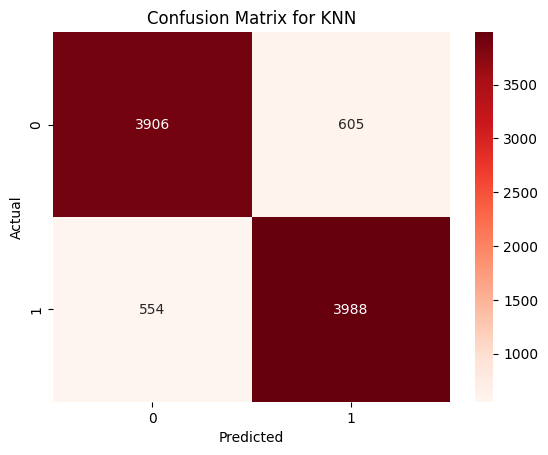

In [40]:
cm_knn = confusion_matrix(y_test,y_pred_knn)
sns.heatmap(cm_knn, annot= True, fmt = 'd', cmap='Reds')
plt.title('Confusion Matrix for KNN')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [47]:
from sklearn.model_selection import GridSearchCV

# defining parameter range
param_grid_knn = {'n_neighbors': [10, 50, 100],
                  'weights': ['uniform', 'distance'],
                  'p': [1, 2]
                  }

grid_knn=GridSearchCV(knn_model, param_grid_knn, cv=2,
                  scoring='accuracy',
                  n_jobs=-1)

In [ ]:



grid_knn.fit(X_train, y_train)

GridSearchCV(cv=2, estimator=KNeighborsClassifier(), n_jobs=-1,
             param_grid={'n_neighbors': [10, 50, 100], 'p': [1, 2],
                         'weights': ['uniform', 'distance']},
             scoring='accuracy')

In [49]:
grid_knn.best_score_
grid_knn.best_params_


{'n_neighbors': 10, 'p': 1, 'weights': 'uniform'}

In [50]:
grid_knn_model = grid_knn.best_estimator_

In [51]:
grid_predictions_knn = grid_knn_model.predict(X_test)

# print classification report
print(classification_report(y_test, grid_predictions_knn))

              precision    recall  f1-score   support

           0       0.87      0.89      0.88      4511
           1       0.89      0.86      0.88      4542

    accuracy                           0.88      9053
   macro avg       0.88      0.88      0.88      9053
weighted avg       0.88      0.88      0.88      9053



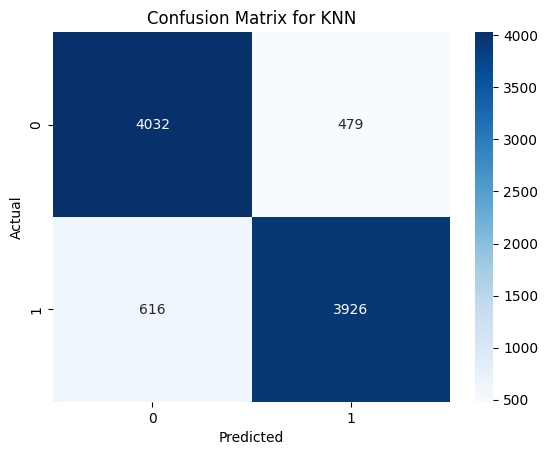

In [52]:
cm_knn_new = confusion_matrix(y_test,grid_predictions_knn)
sns.heatmap(cm_knn_new, annot= True, fmt = 'd', cmap='Blues')
plt.title('Confusion Matrix for KNN')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [18]:
from sklearn import svm
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
import joblib  # Dùng để lưu mô hình



# 2. Lưu mô hình
joblib.dump(grid_knn_model, './model/grid_knn_model.pkl')

# # 3. Tải lại mô hình (khi cần)
# loaded_model = joblib.load('svm_model.pkl')

# # 4. Dự đoán
# y_pred = loaded_model.predict(X_test)

NameError: name 'grid_knn_model' is not defined

# Naive Bayes

In [37]:
from sklearn.naive_bayes import GaussianNB
nb_model = GaussianNB()
nb_model = nb_model.fit(X_train, y_train)
y_pred_nb = nb_model.predict(X_test)
print(classification_report(y_test, y_pred_nb))

              precision    recall  f1-score   support

           0       0.93      0.51      0.66      4511
           1       0.66      0.96      0.78      4542

    accuracy                           0.74      9053
   macro avg       0.79      0.73      0.72      9053
weighted avg       0.79      0.74      0.72      9053



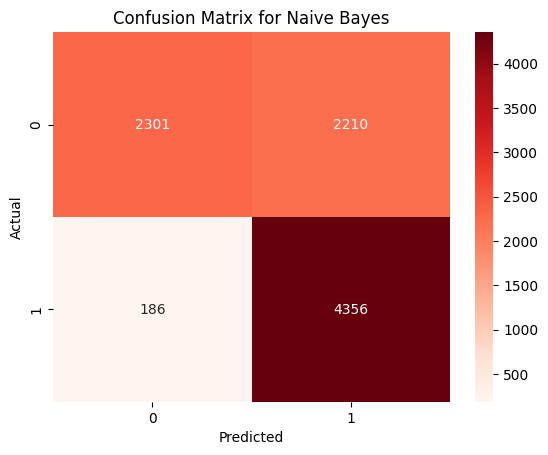

In [38]:
cm_nb = confusion_matrix(y_test,y_pred_nb)
sns.heatmap(cm_nb, annot= True, fmt = 'd', cmap='Reds')
plt.title('Confusion Matrix for Naive Bayes')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# Logistic Regression

In [ ]:
from sklearn.linear_model import LogisticRegression
lr_model = LogisticRegression(max_iter=100, tol=0.01, random_state=42)
lr_model = lr_model.fit(X_train, y_train)
y_pred_lr = lr_model.predict(X_test)
print(classification_report(y_test, y_pred_lr))

              precision    recall  f1-score   support

           0       0.86      0.89      0.87      4511
           1       0.89      0.86      0.87      4542

    accuracy                           0.87      9053
   macro avg       0.87      0.87      0.87      9053
weighted avg       0.87      0.87      0.87      9053



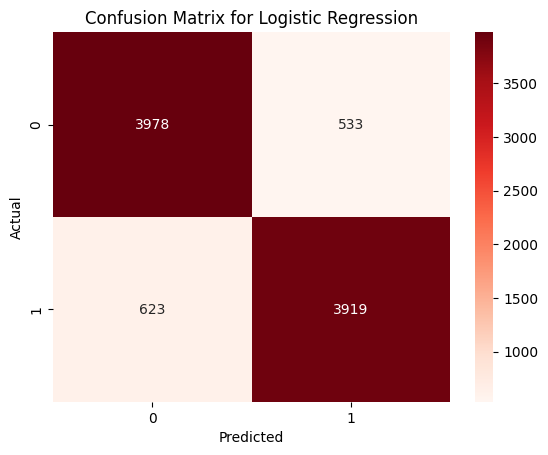

In [21]:
cm_lr = confusion_matrix(y_test,y_pred_lr)
sns.heatmap(cm_lr, annot= True, fmt = 'd', cmap='Reds')
plt.title('Confusion Matrix for Logistic Regression')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

Tối ưu tham số

In [ ]:
from sklearn.model_selection import GridSearchCV
# defining parameter range
param_grid_lr = {'C': [1, 0.1, 0.01, 0.001, 0.0001],
			'tol': [1, 0.1, 0.01, 0.001, 0.0001],
            'max_iter': [100, 200],
			'solver': [ 'lbfgs']}

grid_lr=GridSearchCV(lr_model, param_grid_lr, cv=2,
                  scoring='accuracy',
                  n_jobs=-1)

In [23]:
grid_lr.fit(X_train, y_train)

GridSearchCV(cv=2, estimator=LogisticRegression(random_state=42, tol=0.01),
             n_jobs=-1,
             param_grid={'C': [1, 0.1, 0.01, 0.001, 0.0001],
                         'max_iter': [100, 200], 'solver': ['lbfgs'],
                         'tol': [1, 0.1, 0.01, 0.001, 0.0001]},
             scoring='accuracy')

In [24]:
grid_lr.best_score_

np.float64(0.8786489835706989)

In [25]:
grid_lr.best_params_

{'C': 1, 'max_iter': 100, 'solver': 'lbfgs', 'tol': 0.0001}

In [26]:
model_lr_new = grid_lr.best_estimator_

In [ ]:
grid_predictions_lr = model_lr_new.predict(X_test)
# print classification report
print(classification_report(y_test, grid_predictions_lr))

              precision    recall  f1-score   support

           0       0.87      0.89      0.88      4511
           1       0.89      0.87      0.88      4542

    accuracy                           0.88      9053
   macro avg       0.88      0.88      0.88      9053
weighted avg       0.88      0.88      0.88      9053



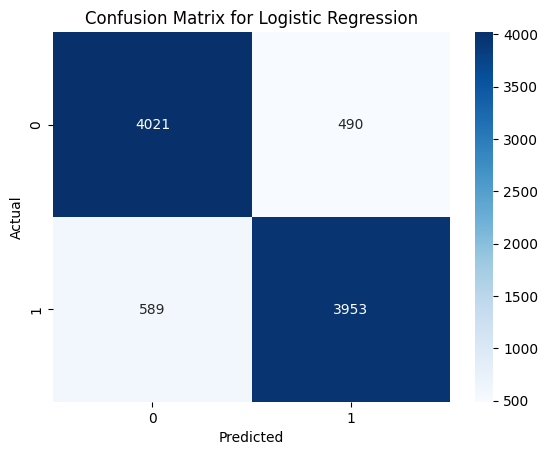

In [28]:
cm_lr_new = confusion_matrix(y_test,grid_predictions_lr)
sns.heatmap(cm_lr_new, annot= True, fmt = 'd', cmap='Blues')
plt.title('Confusion Matrix for Logistic Regression')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [29]:
from sklearn import svm
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
import joblib  # Dùng để lưu mô hình



# 2. Lưu mô hình
joblib.dump(model_lr_new, './model/grid_lr_model.pkl')

['./model/grid_lr_model.pkl']

# SVM


In [44]:
from sklearn.svm import SVC
svm_model = SVC( kernel='linear', C=1, random_state=42, gamma=1)
svm_model = svm_model.fit(X_train, y_train)
y_pred_svm = svm_model.predict(X_test)
print(classification_report(y_test, y_pred_svm))

              precision    recall  f1-score   support

           0       0.87      0.87      0.87      4511
           1       0.87      0.87      0.87      4542

    accuracy                           0.87      9053
   macro avg       0.87      0.87      0.87      9053
weighted avg       0.87      0.87      0.87      9053



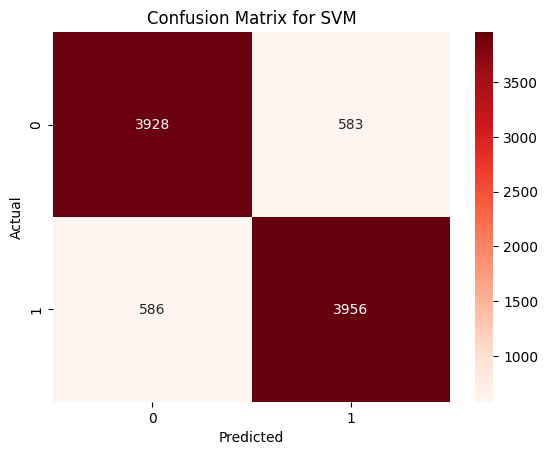

In [31]:
cm_svm = confusion_matrix(y_test,y_pred_svm)
sns.heatmap(cm_svm, annot= True, fmt = 'd', cmap='Reds')
plt.title('Confusion Matrix for SVM')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

Tối ưu tham số bằng grid search

In [32]:
from sklearn.model_selection import GridSearchCV

# defining parameter range
param_grid_svm = {'C': [0.1, 1, 10, 100],
			'gamma': [1, 0.1, 0.01, 0.001, 0.0001],
			'kernel': [ 'rbf']}

grid_svm=GridSearchCV(svm_model, param_grid_svm, cv=3,
                  scoring='accuracy',
                  n_jobs=-1)

In [33]:

grid_svm.fit(X_train, y_train)



GridSearchCV(cv=3, estimator=SVC(C=1, kernel='linear', random_state=42),
             n_jobs=-1,
             param_grid={'C': [0.1, 1, 10, 100],
                         'gamma': [1, 0.1, 0.01, 0.001, 0.0001],
                         'kernel': ['rbf']},
             scoring='accuracy')

In [35]:
grid_svm.best_score_

np.float64(0.8802506983171353)

In [36]:
grid_svm.best_params_

{'C': 10, 'gamma': 0.1, 'kernel': 'rbf'}

In [37]:
grid_svm_model = grid_svm.best_estimator_

In [38]:
# Dự đoán thử và in báo cáo
grid_predictions_svm = grid_svm_model.predict(X_test)

# print classification report
print(classification_report(y_test, grid_predictions_svm))

              precision    recall  f1-score   support

           0       0.87      0.90      0.88      4511
           1       0.90      0.87      0.88      4542

    accuracy                           0.88      9053
   macro avg       0.88      0.88      0.88      9053
weighted avg       0.88      0.88      0.88      9053



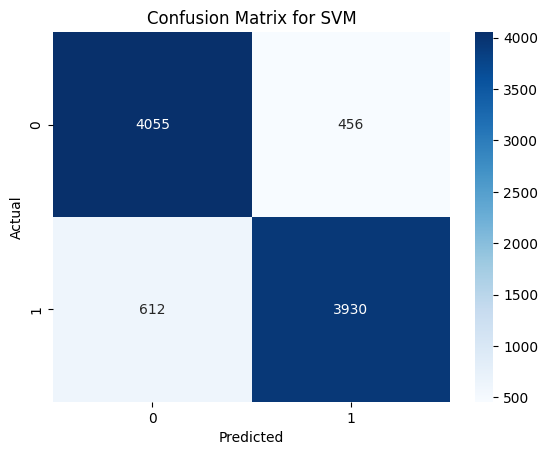

In [47]:
grid_cm_svm = confusion_matrix(y_test,grid_predictions_svm)
sns.heatmap(cm_svm, annot= True, fmt = 'd', cmap='Blues')
plt.title('Confusion Matrix for SVM')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [50]:
from sklearn import svm
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
import joblib  # Dùng để lưu mô hình



# 2. Lưu mô hình
joblib.dump(grid_svm_model, './model/grid_svm_model.pkl')

['./model/grid_svm_model.pkl']

Tối ưu hóa tham số bằng Random Search

In [40]:
from sklearn.model_selection import RandomizedSearchCV
param_random_svm = {'C': [0.1, 1, 10, 100],
			'gamma': [1, 0.1, 0.01, 0.001, 0.0001],
			'kernel': [ 'rbf']}

In [41]:
random_grid_search = RandomizedSearchCV(svm_model,
                                        param_random_svm,
                                        cv=3,
                                        scoring='accuracy',
                                        n_jobs=-1,
                                        random_state=26)

In [42]:

random_grid_search.fit(X_train, y_train)

RandomizedSearchCV(cv=3, estimator=SVC(C=1, kernel='linear', random_state=42),
                   n_jobs=-1,
                   param_distributions={'C': [0.1, 1, 10, 100],
                                        'gamma': [1, 0.1, 0.01, 0.001, 0.0001],
                                        'kernel': ['rbf']},
                   random_state=26, scoring='accuracy')

In [43]:
random_grid_search.best_score_

np.float64(0.8802506983171353)

In [44]:
random_grid_search.best_params_

{'kernel': 'rbf', 'gamma': 0.1, 'C': 10}

In [45]:
model_random_search = random_grid_search.best_estimator_

In [46]:
# Dự đoán thử và in báo cáo
random_predictions_svm = model_random_search.predict(X_test)

# print classification report
print(classification_report(y_test, random_predictions_svm))

              precision    recall  f1-score   support

           0       0.87      0.90      0.88      4511
           1       0.90      0.87      0.88      4542

    accuracy                           0.88      9053
   macro avg       0.88      0.88      0.88      9053
weighted avg       0.88      0.88      0.88      9053



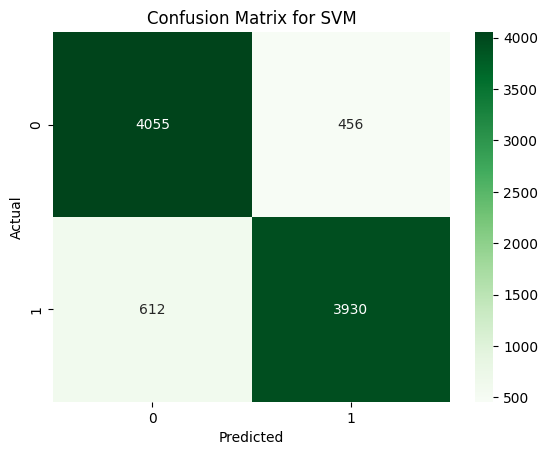

In [49]:
random_cm_svm = confusion_matrix(y_test,random_predictions_svm)
sns.heatmap(cm_svm, annot= True, fmt = 'd', cmap='Greens')
plt.title('Confusion Matrix for SVM')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# Decision Tree

In [36]:
# 'criterion': 'entropy', 'max_depth': 100, 'splitter': 'random'

from sklearn.tree import DecisionTreeClassifier
decision_tree_model = DecisionTreeClassifier( max_depth=100, random_state=42, criterion='gini', splitter='best')
decision_tree_model = decision_tree_model.fit(X_train, y_train)
y_pred_dt = decision_tree_model.predict(X_test)
print(classification_report(y_test, y_pred_dt))

              precision    recall  f1-score   support

           0       0.85      0.83      0.84      4511
           1       0.84      0.85      0.84      4542

    accuracy                           0.84      9053
   macro avg       0.84      0.84      0.84      9053
weighted avg       0.84      0.84      0.84      9053



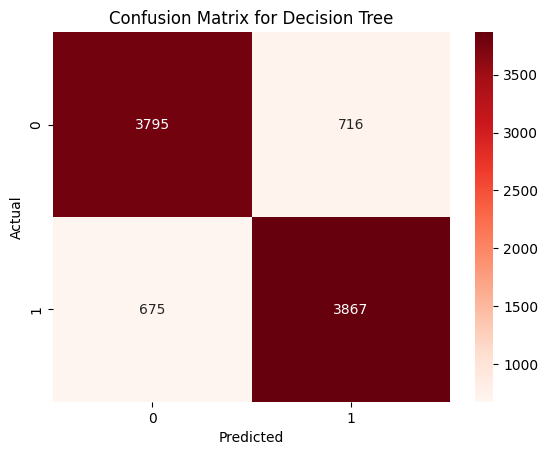

In [30]:
cm_dt = confusion_matrix(y_test,y_pred_dt)
sns.heatmap(cm_dt, annot= True, fmt = 'd', cmap='Reds')
plt.title('Confusion Matrix for Decision Tree')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

Tối ưu bằng grid search

In [31]:
from sklearn.model_selection import GridSearchCV

# defining parameter range
param_grid_dt = {'max_depth': [100, 200, 300, 400],
                 'criterion': ['gini', 'entropy', 'log_loss'] ,
                'splitter': ['best', 'random'] ,
                 }

grid_dt=GridSearchCV(decision_tree_model , param_grid_dt, cv=5,
                  scoring='accuracy',
                  n_jobs=-1)

In [32]:
grid_dt.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=DecisionTreeClassifier(criterion='entropy',
                                              max_depth=100, random_state=42),
             n_jobs=-1,
             param_grid={'criterion': ['gini', 'entropy', 'log_loss'],
                         'max_depth': [100, 200, 300, 400],
                         'splitter': ['best', 'random']},
             scoring='accuracy')

In [ ]:
grid_dt.best_params_
# max_depth=100, random_state=42, criterion='gini', splitter='best'

{'criterion': 'entropy', 'max_depth': 100, 'splitter': 'random'}

In [34]:
grid_dt_model = grid_dt.best_estimator_

In [35]:
grid_predictions_dt = grid_dt_model.predict(X_test)

# print classification report
print(classification_report(y_test,grid_predictions_dt ))

              precision    recall  f1-score   support

           0       0.86      0.84      0.85      4511
           1       0.85      0.86      0.85      4542

    accuracy                           0.85      9053
   macro avg       0.85      0.85      0.85      9053
weighted avg       0.85      0.85      0.85      9053



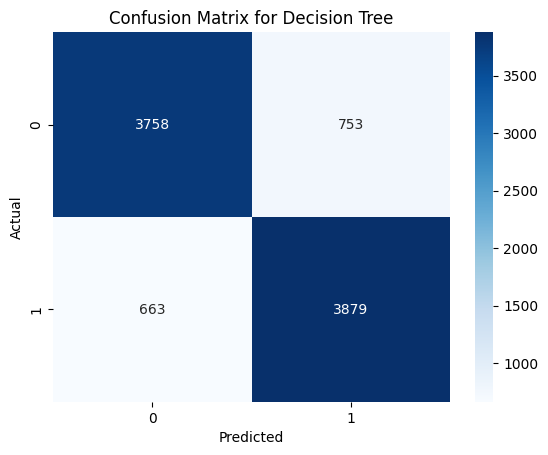

In [64]:
cm_dt_grid = confusion_matrix(y_test,grid_predictions_dt)
sns.heatmap(cm_dt_grid, annot= True, fmt = 'd', cmap='Blues')
plt.title('Confusion Matrix for Decision Tree')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# Random Forest


In [50]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, max_depth=100)
# rf_model = RandomForestClassifier(n_estimators=200, random_state=42, max_depth=10, criterion='entropy', min_samples_split=2)
rf_model = rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)
print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       0.88      0.89      0.88      4511
           1       0.89      0.87      0.88      4542

    accuracy                           0.88      9053
   macro avg       0.88      0.88      0.88      9053
weighted avg       0.88      0.88      0.88      9053



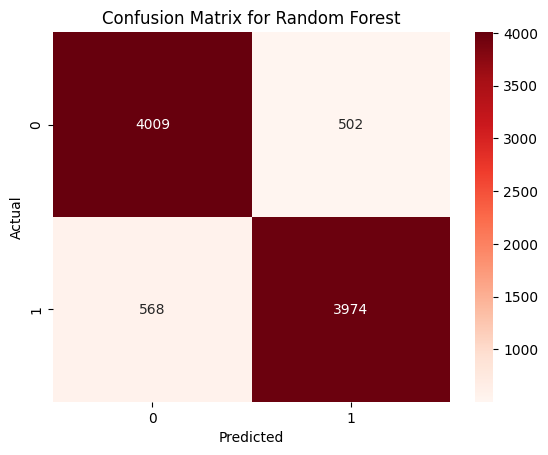

In [67]:
cm_rf = confusion_matrix(y_test,y_pred_rf)
sns.heatmap(cm_rf, annot= True, fmt = 'd', cmap='Reds')
plt.title('Confusion Matrix for Random Forest')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [45]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

param_grid_rf = {
    'n_estimators': [100, 200, 300],
    'max_depth': [ 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'criterion': ['gini', 'entropy', 'log_loss']
    
    
}


grid_rf_model = GridSearchCV(rf_model, param_grid_rf, cv=5, scoring='accuracy', n_jobs=-1)
grid_rf_model.fit(X_train, y_train)



KeyboardInterrupt: 

In [ ]:
grid_rf_model.best_params_

In [ ]:
grid_rf_model = grid_dt.best_estimator_

In [ ]:
grid_predictions_rf = grid_rf_model.predict(X_test)

# print classification report
print(classification_report(y_test,grid_predictions_rf ))

In [68]:
from sklearn import svm
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
import joblib  # Dùng để lưu mô hình



# 2. Lưu mô hình
joblib.dump(rf_model, './model/rf_model.pkl')

['./model/rf_model.pkl']

# Gradient Boosting

In [40]:
from sklearn.ensemble import GradientBoostingClassifier


gb_model = GradientBoostingClassifier(learning_rate=0.01, random_state=42,n_estimators=200)

gb_model.fit(X_train, y_train)
y_pred_gb = gb_model.predict(X_test)
print(classification_report(y_test, y_pred_gb))

              precision    recall  f1-score   support

           0       0.88      0.81      0.84      4511
           1       0.82      0.89      0.85      4542

    accuracy                           0.85      9053
   macro avg       0.85      0.85      0.85      9053
weighted avg       0.85      0.85      0.85      9053



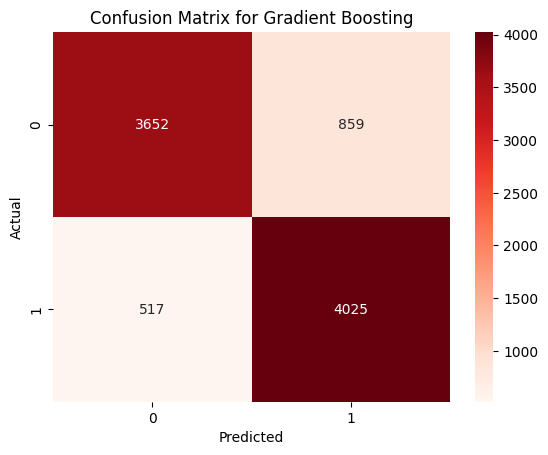

In [70]:
cm_gb = confusion_matrix(y_test,y_pred_gb)
sns.heatmap(cm_gb, annot= True, fmt = 'd', cmap='Reds')
plt.title('Confusion Matrix for Gradient Boosting')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [41]:
from sklearn.model_selection import GridSearchCV

# defining parameter range
param_grid_gb = {'n_estimators': [1, 10, 100],
              'max_depth': [1, 10, 100],
			'learning_rate': [0.1, 0.01, 0.001],
			}

grid_gb=GridSearchCV(gb_model, param_grid_gb, cv=3,
                  scoring='accuracy',
                  n_jobs=-1)

In [42]:
grid_gb.fit(X_train, y_train)

GridSearchCV(cv=3,
             estimator=GradientBoostingClassifier(learning_rate=0.01,
                                                  n_estimators=200,
                                                  random_state=42),
             n_jobs=-1,
             param_grid={'learning_rate': [0.1, 0.01, 0.001],
                         'max_depth': [1, 10, 100],
                         'n_estimators': [1, 10, 100]},
             scoring='accuracy')

In [ ]:
grid_gb.best_params_


# learning_rate=0.01, random_state=42,n_estimators=200, max_depth = 3



{'learning_rate': 0.1, 'max_depth': 10, 'n_estimators': 100}

In [73]:
grid_gb_model = grid_gb.best_estimator_

In [74]:
# Dự đoán thử và in báo cáo
grid_predictions_gb = grid_gb_model.predict(X_test)

# print classification report
print(classification_report(y_test, grid_predictions_gb


))

              precision    recall  f1-score   support

           0       0.88      0.89      0.89      4511
           1       0.89      0.88      0.89      4542

    accuracy                           0.89      9053
   macro avg       0.89      0.89      0.89      9053
weighted avg       0.89      0.89      0.89      9053



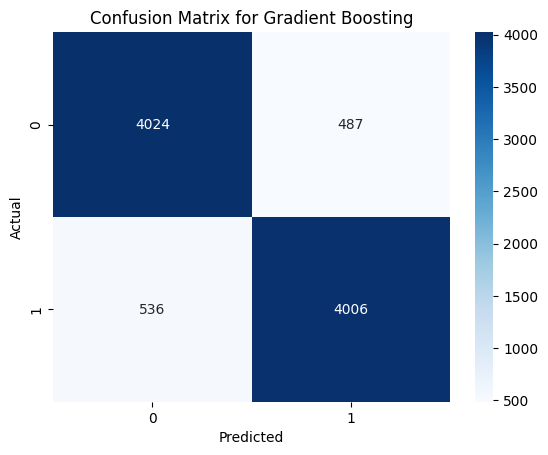

In [75]:
cm_gb_grid = confusion_matrix(y_test,grid_predictions_gb)
sns.heatmap(cm_gb_grid, annot= True, fmt = 'd', cmap='Blues')
plt.title('Confusion Matrix for Gradient Boosting')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [76]:
from sklearn import svm
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
import joblib  # Dùng để lưu mô hình



# 2. Lưu mô hình
joblib.dump(grid_gb_model, './model/grid_gb_model.pkl')

['./model/grid_gb_model.pkl']

# XGBoost


In [82]:
import xgboost as xgb

model_xgb = xgb.XGBClassifier(random_state=42, n_estimators = 200)

model_xgb.fit(X_train, y_train)
y_pred_xg = model_xgb.predict(X_test)
print(classification_report(y_test, y_pred_xg))

              precision    recall  f1-score   support

           0       0.88      0.89      0.89      4511
           1       0.89      0.88      0.88      4542

    accuracy                           0.89      9053
   macro avg       0.89      0.89      0.89      9053
weighted avg       0.89      0.89      0.89      9053



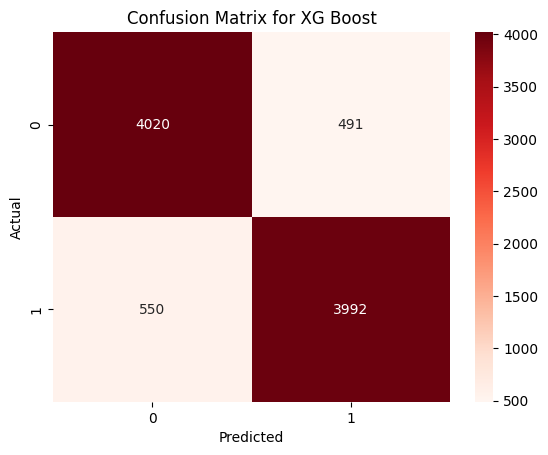

In [83]:
cm_xg = confusion_matrix(y_test,y_pred_xg)
sns.heatmap(cm_xg, annot= True, fmt = 'd', cmap='Reds')
plt.title('Confusion Matrix for XG Boost')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [84]:
from sklearn import svm
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
import joblib  # Dùng để lưu mô hình



# 2. Lưu mô hình
joblib.dump(model_xgb, './model/xgb_model.pkl')

['./model/xgb_model.pkl']

# LightGBM


In [ ]:
import lightgbm as lgb
from sklearn.metrics import classification_report, confusion_matrix
train_gbm = lgb.Dataset(X_train, label=y_train)
test_data = lgb.Dataset(X_test, label=y_test, reference=train_gbm)
params_gbm = {
    'objective': 'binary', # Mục tiêu là phân loại nhị phân
    'metric': 'binary_error', # Đánh giá theo chỉ số lỗi phân loại nhị phân
    'boosting_type': 'gbdt', # Sử dụng GBDT (Gradient Boosting Decision Tree)
    'num_leaves': 31, # Số lượng lá cây quyết định
    'learning_rate': 0.05, # Tốc độ học
    'feature_fraction': 0.9, # Tỷ lệ đặc trưng sử dụng trong mỗi cây
    
}
gbm_model = lgb.train( params_gbm,
    train_gbm,
    valid_sets=[test_data],
    valid_names=['eval'],  # Thêm tên cho tập validation
    num_boost_round=200, # Số vòng lặp tăng cường
    callbacks=[lgb.early_stopping(stopping_rounds=10)]  # Dùng callback thay vì keyword trực tiếp
                      )
y_pred_gbm = gbm_model.predict(X_test)
print(classification_report(y_test, y_pred_gbm.round()))

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 18089, number of negative: 18120
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.016504 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 590
[LightGBM] [Info] Number of data points in the train set: 36209, number of used features: 79
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.499572 -> initscore=-0.001712
[LightGBM] [Info] Start training from score -0.001712
Training until validation scores don't improve for 10 rounds
Early stopping, best iteration is:
[73]	eval's binary_error: 0.112007
              precision    recall  f1-score   support

           0       0.88      0.90      0.89      4511
           1       0.90      0.87      0.89

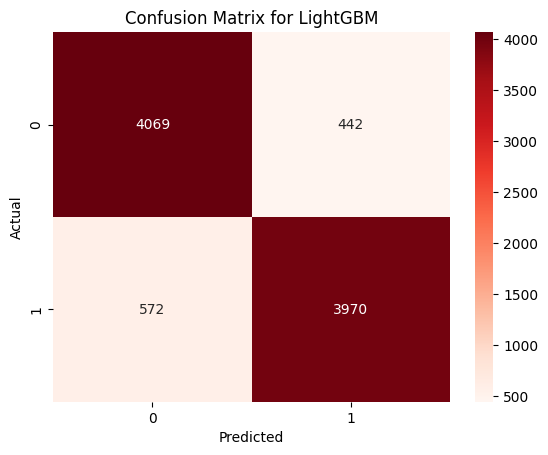

In [51]:
cm_lgb = confusion_matrix(y_test,y_pred_gbm.round())
sns.heatmap(cm_lgb, annot= True, fmt = 'd', cmap='Reds')
plt.title('Confusion Matrix for LightGBM')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [24]:
from sklearn import svm
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
import joblib  # Dùng để lưu mô hình



# 2. Lưu mô hình
joblib.dump(gbm_model, './model/gbm_model.pkl')

['./model/gbm_model.pkl']